# Fase 2 — $a_j$ por región y diagnóstico de la FCD

**Idea.** $a_j$ fija el amortiguamiento de cada región y, por lo tanto, cuánto tarda en decaer la autocorrelación de su BOLD. Ajustamos $(a_1,\dots,a_N,G)$, 95 parámetros, a la FC filtrada **y** a las autocorrelaciones regionales a 2, 5, 10 y 20 s. Todo se calcula de forma analítica con la linealización (`hopf.FilteredSpectrum`, unos 25 ms por evaluación) y se optimiza con L-BFGS sobre $\log|a_j|$ y $\log G$:
$$\mathcal L = \mathrm{MSE}(\mathrm{FC}) + \mathrm{MSE}(\mathrm{AC}) + 10^{-3}\,\mathrm{Var}(\log|a|).$$
Validación: ajustamos con 4 sujetos y evaluamos en los otros 3, contra el modelo homogéneo y contra $a_j$ barajados espacialmente. Código: `src/fit_heterogeneous.py` y `src/surrogate_fcd.py`.

homog. train    MSE_FC=0.0386  MSE_AC=0.0073  r(FC)=0.551
heterog. train  MSE_FC=0.0333  MSE_AC=0.0075  r(FC)=0.628
homog. test     MSE_FC=0.0653  MSE_AC=0.0058  r(FC)=0.425
heterog. test   MSE_FC=0.0595  MSE_AC=0.0059  r(FC)=0.479
barajado test   MSE_FC=0.0556  MSE_AC=0.0069  r(FC)=0.425
reproducibilidad del mapa a_j entre mitades: r = 0.68


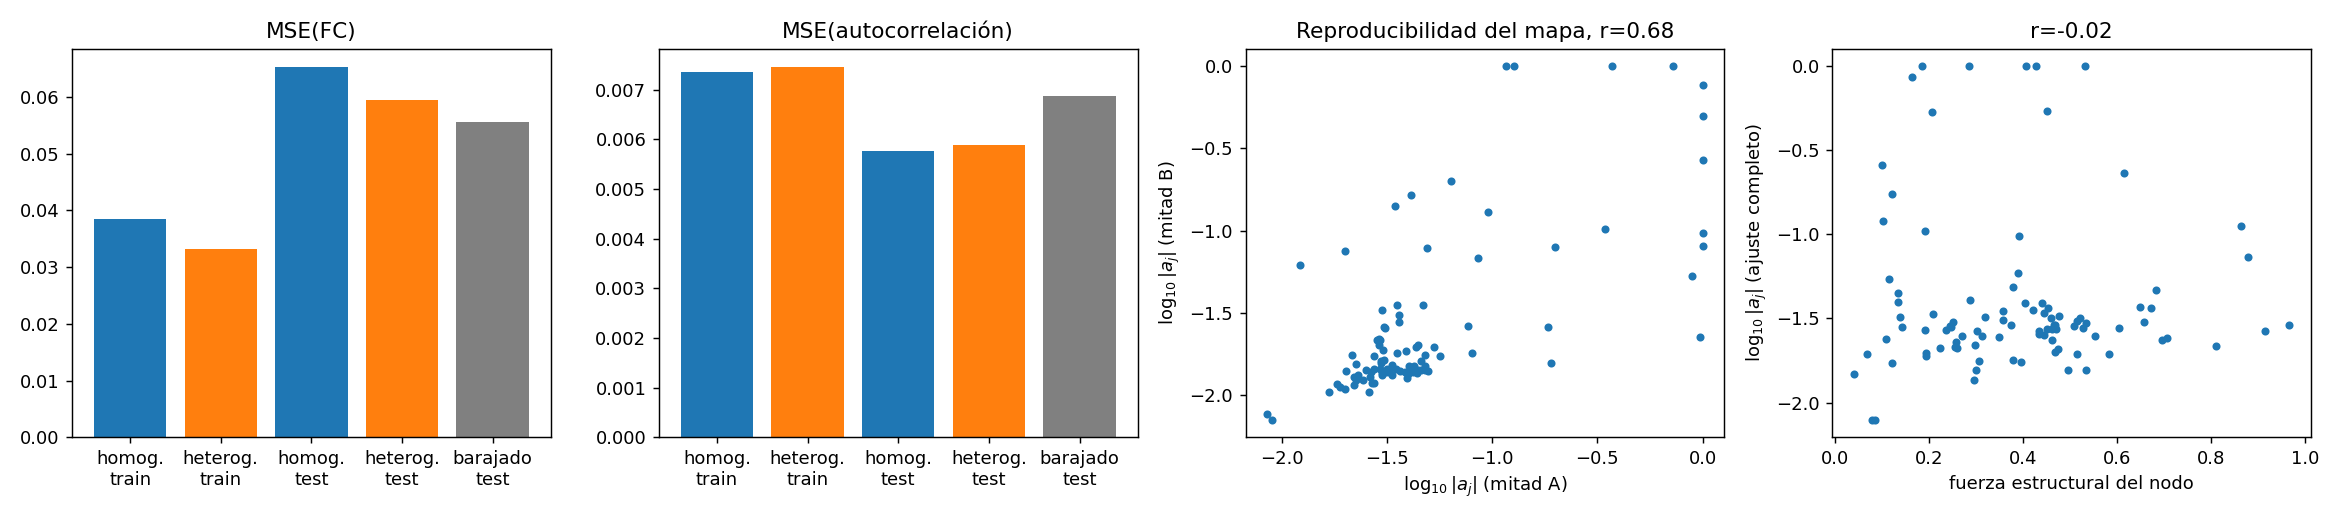

In [1]:
import numpy as np
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
r = np.load(ROOT/'results'/'fase2_heterogeneous.npz')
names = ['homog. train','heterog. train','homog. test','heterog. test','barajado test']
for n, (f, c, rr) in zip(names, r['cv']): print(f"{n:15s} MSE_FC={f:.4f}  MSE_AC={c:.4f}  r(FC)={rr:.3f}")
print(f"reproducibilidad del mapa a_j entre mitades: r = {float(r['rel']):.2f}")
display(Image(str(ROOT/'figures'/'fase2_validacion_cruzada.png')))

**Resultado del ajuste.**
- Hay mejora modesta y parcialmente específica en el espacio: el $r$(FC) en los sujetos de prueba sube de 0.43 a 0.48, mientras que barajar las $a_j$ lo regresa a 0.43. El mapa de $a_j$ es moderadamente reproducible entre mitades ($r=0.68$).
- **No** mejora las autocorrelaciones regionales. El MSE de AC queda igual y la AC simulada de cada región no se correlaciona con la empírica. A 5–20 s la autocorrelación la dominan el filtro y $\omega_j$, no $a_j$.
- Unas 14 regiones se van al límite $a_j\to-1$, es decir, quedan "apagadas". Son regiones con FC empírica baja o negativa, como el bloque 22–25 con franjas negativas ($r(\log|a_j|,\ \text{FC media}) = -0.61$). El ajuste las desacopla porque el modelo no puede generar anticorrelaciones. **Es una compensación de un error de especificación, no un hallazgo fisiológico.**
- Al incluir la autocorrelación en el objetivo, el ajuste homogéneo se mueve a $a\approx-0.07$, con un tiempo de relajación $1/\delta\approx 14$ s. Los datos piden más amortiguamiento que el borde exacto de la bifurcación ($a\to0$) que favorecía el ajuste solo por FC.

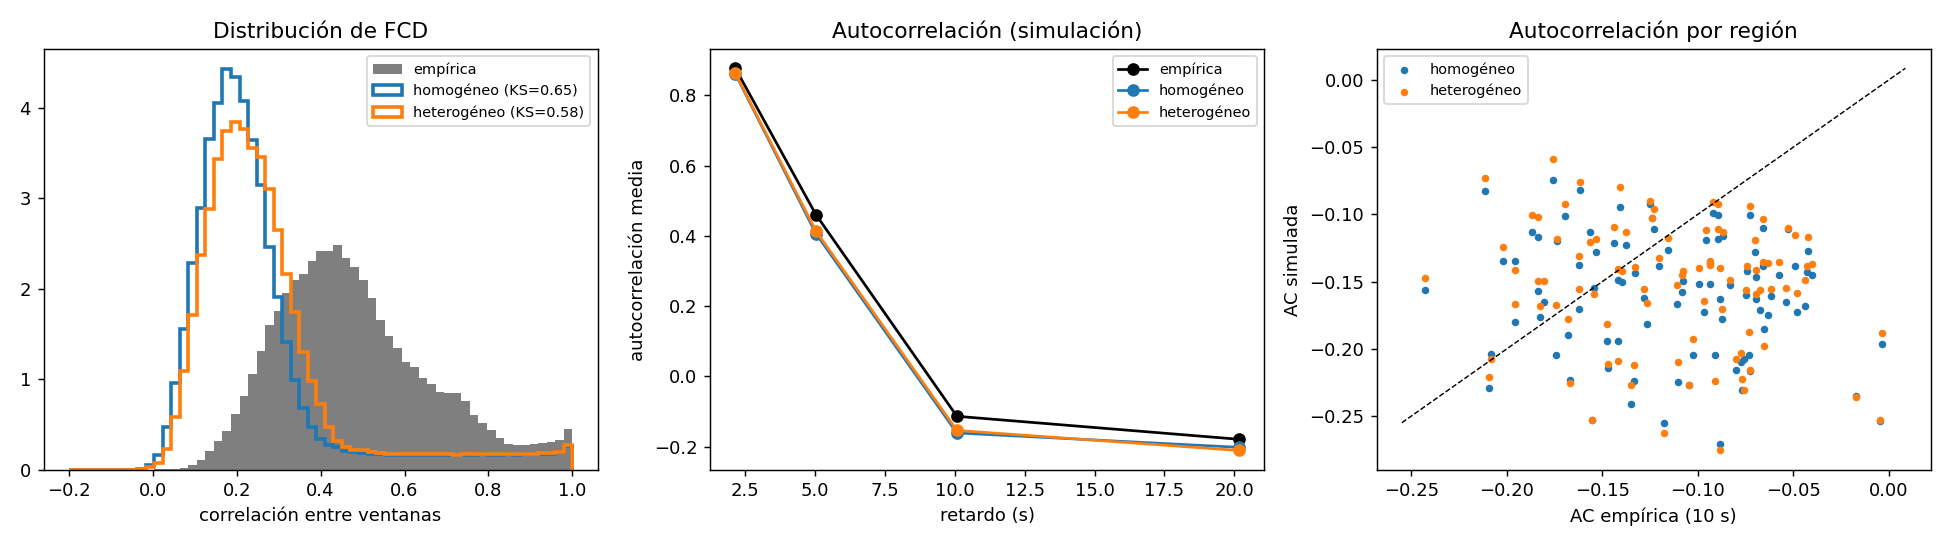

homogéneo    r(FC)=0.512  FC media=0.313  KS(FCD)=0.647  metaest.=0.186
heterogéneo  r(FC)=0.599  FC media=0.319  KS(FCD)=0.578  metaest.=0.185
empírico     FC media=0.373  metaest.=0.176


In [2]:
display(Image(str(ROOT/'figures'/'fase2_no_lineal.png')))
for k, (rr, mf, ks, me) in zip(['homogéneo','heterogéneo'], r['nl']):
    print(f"{k:12s} r(FC)={rr:.3f}  FC media={mf:.3f}  KS(FCD)={ks:.3f}  metaest.={me:.3f}")
print(f"empírico     FC media=0.373  metaest.={r['meta_emp'].mean():.3f}")

## Diagnóstico: ¿qué necesita un modelo para reproducir la FCD?

**Surrogados de fase multivariados.** Se aplica la misma fase aleatoria a todas las regiones en cada frecuencia. Esto preserva *exactamente* los espectros y la FC empírica, pero produce un proceso **gaussiano, lineal y estacionario**.

| | FCD media / DE | KS frente a la empírica | metaestabilidad |
|---|---|---|---|
| empírica | 0.48 / 0.18 | — | 0.176 |
| surrogado de fase | 0.50 / 0.17 | **0.07** | **0.175** |
| empírica con GSR | 0.40 / 0.17 | — | |
| surrogado con GSR | 0.41 / 0.16 | 0.10 | |

**Conclusión.** En estos datos (7 sujetos HCP, 60 s por ventana), **la FCD y la metaestabilidad se explican por completo con un proceso lineal estacionario que tenga la FC y los espectros correctos.** Esto coincide con Liégeois et al. (2017, *NeuroImage*). De ahí salen dos consecuencias:
1. El modelo no falla en la FCD por "falta de dinámica no lineal". Falla porque su estructura de covarianza cruzada no es la correcta: su FC tiene $r\approx0.5$ con la empírica y es más "plana", así que las ventanas quedan dominadas por ruido de muestreo y la FCD media sale baja. **El cuello de botella es la conectividad, no la dinámica local**, y eso apunta a la **conectividad efectiva** como siguiente paso.
2. Esto pesa en el programa de investigación: **ni la FCD ni la metaestabilidad son evidencia de criticalidad**. Para medir la distancia a la bifurcación necesitamos observables que distingan un proceso lineal estable de uno cercano a una bifurcación de Hopf. Candidatos: estadísticos no gaussianos (curtosis, asimetría de las envolventes), irreversibilidad temporal, o la tendencia de las autocorrelaciones a lo largo de una variable lenta (edad, patología).

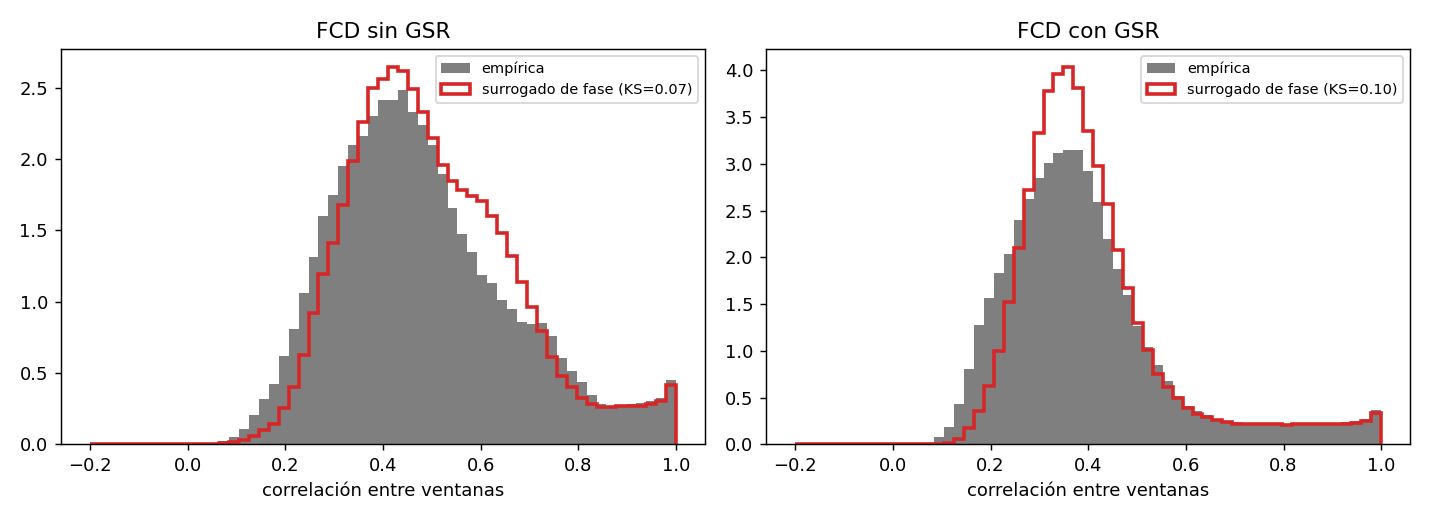

In [3]:
display(Image(str(ROOT/'figures'/'fase2_surrogados_fcd.png')))